In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
from matplotlib.ticker import FuncFormatter
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

## load data from banned subreddits

In [2]:
from src.utils.data_loader_polars import load_filtered_data

years = range(2006, 2020)
cols = ["id","author","subreddit","created_utc"]

def load_post_subreddit(subm_input_fpath, comm_input_fpath, years=years, cols=cols):
    subm_df = load_filtered_data(years=years, data_dir=subm_input_fpath, filetype="submissions",filter_bots=False).select(cols)
    comm_df = load_filtered_data(years=years, data_dir=comm_input_fpath, filetype="comments",filter_bots=False).select(cols)
    subm_df = subm_df.with_columns(pl.lit("submission").alias("kind"))
    comm_df = comm_df.with_columns(pl.lit("comment").alias("kind"))
    post_df = pl.concat([subm_df, comm_df], how="vertical").filter(pl.col("subreddit").is_not_null())
    return post_df

subm_input_banned = f"{DATAPATH}/filtered-data-new/submissions/subm-from-user-banned-2020-subset3274-lite/" 
comm_input_banned = f"{DATAPATH}/filtered-data-new/comments/comm-from-user-banned-2020-subset3274-lite/" 
post_banned = load_post_subreddit(subm_input_banned, comm_input_banned)


******************
Loading Submissions from /cinddata/reddit-ban-study/filtered-data-new/submissions/subm-from-user-banned-2020-subset3274-lite/...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009


	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019
******************
Loading Comments from /cinddata/reddit-ban-study/filtered-data-new/comments/comm-from-user-banned-2020-subset3274-lite/...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019


In [3]:
# define subreddit sets and configure parameters
sets_df = pd.read_csv("../../data-public/subreddit_sets.csv")

subreddit_sets = {
    name: set(group["subreddit"])
    for name, group in sets_df.groupby("set")
}
banned = subreddit_sets["banned"]
print(len(banned))

def normalize_subreddit(x):
    return str(x).lower().strip()

banned_set = {normalize_subreddit(x) for x in banned}
focal = "the_donald"

YEARS = list(range(2006, 2020))
FOCUS_YEARS = range(2014, 2020)

3274


## retrieve all posts from banned subreddits

In [4]:
posts = (
    post_banned
    .filter(~pl.col("author").is_in(["[deleted]", "[removed]"]))
    .select("author", "subreddit", "created_utc")
    .with_columns(
        pl.from_epoch("created_utc", time_unit="ms").dt.year().alias("year")
    )
)

# if we only want to include users who posted in at least two distinct banned subreddits.
eligible_authors = (
    posts
    .filter(pl.col("subreddit").is_in(list(banned_set)))
    .filter(pl.col("year").is_between(2014, 2019)) 
    .group_by("author")
    .agg(pl.col("subreddit").n_unique().alias("n_banned_subs"))
    .filter(pl.col("n_banned_subs") >= 2)
    .select("author")
)

posts = posts.join(eligible_authors, on="author", how="semi")

tagged = (
    posts
    .with_columns(
        pl.col("subreddit").is_in(list(banned_set)).alias("is_banned"),
    )
)

In [5]:
# use new user count as a reference
new_banned_sizes = (
    posts
    .filter(pl.col("subreddit").is_in(list(banned_set)))
    .group_by(["author", "subreddit"])
    .agg(pl.col("created_utc").min().alias("first_post_utc"))
    .with_columns(
        pl.from_epoch("first_post_utc", time_unit="ms").dt.year().alias("year")
    )
    .group_by(["year", "subreddit"])
    .agg(pl.len().alias("n_author"))
    .to_pandas()
)

## identify entry points into banned subreddits

In [6]:
# identify entrants into banned subreddits for each year
first_b = (
    tagged
    .filter(pl.col("is_banned"))
    .group_by("author")
    .agg(pl.col("created_utc").min().alias("t_b"))
)

# Identify the subreddit at the first banned timestamp.
# Count distinct subreddits because multiple posts to the same
# subreddit at that timestamp are still an unambiguous entry point.
first_b_subreddit = (
    tagged
    .filter(pl.col("is_banned"))
    .join(
        first_b,
        left_on=["author", "created_utc"],
        right_on=["author", "t_b"],
        how="inner",
    )
    .group_by("author")
    .agg(
        pl.col("subreddit").min().alias("b_subreddit"),
        pl.col("subreddit").n_unique().alias("n_first_b_subs"),
    )
)


mb_all = (
    first_b
    .join(first_b_subreddit, on="author")
    .with_columns(
        pl.from_epoch("t_b", time_unit="ms").dt.year().alias("year")
    )
    .filter(pl.col("year").is_in(FOCUS_YEARS))
)

# Exclude users whose first banned timestamp contains posts
# in multiple distinct banned subreddits.
mb_entry = mb_all.filter(pl.col("n_first_b_subs") == 1)

print("Users with first banned post in multiple distinct subreddits:", len(mb_all.filter(pl.col("n_first_b_subs") > 1)))
print(f"Eligible entrants to B in 2014-2019: {mb_all.height:,}")
print(f"Eligible entrants to B in 2014-2019 (after filtering): {mb_entry.height:,}")

cohort_n = mb_entry.group_by("year").agg(pl.len().alias("n_routes")).to_pandas()
entry_counts = (
    mb_entry
    .group_by(["year", "b_subreddit"])
    .agg(pl.len().alias("n_users"))
    .rename({"b_subreddit": "subreddit"})
    .to_pandas()
)
display(cohort_n)
display(entry_counts)

Users with first banned post in multiple distinct subreddits: 3
Eligible entrants to B in 2014-2019: 264,287
Eligible entrants to B in 2014-2019 (after filtering): 264,284


,year,n_routes
0,2017,37941
1,2018,60059
2,2016,47894
3,2015,11745
4,2019,99087
5,2014,7558


,year,subreddit,n_users
0,2018,pantyslips,1
1,2017,adorablegirls,2
2,2019,jab,3
3,2019,curvygifs,10
4,2019,legionofskanks,169
...,...,...,...
5916,2016,vrpornsites,1
5917,2019,lais_deleon,1
5918,2017,lyingonbellynsfw,9
5919,2018,animetiddies,2


## build Poisson regression to establish a expected baseline

In [7]:
import warnings
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationError
from scipy.sparse import csr_matrix
from scipy.stats import spearmanr
from adjustText import adjust_text

PLOT_YEARS = list(range(2014, 2020))
N_BOOT = 1000
BOOT_SEED = 42
TOP_K = 5
MIN_FIRST_ENTRIES_TO_PLOT = 0

In [8]:
# U: first-time participants in each subreddit, among the eligible population.
# O: first entries into the entire banned set, after excluding ambiguous entries.
gatekeeper_df = (
    new_banned_sizes.loc[
        new_banned_sizes["year"].isin(PLOT_YEARS) & (new_banned_sizes["n_author"] > 0),
        ["year", "subreddit", "n_author"],
    ]
    .rename(columns={"n_author": "new_user_count"})
    .merge(entry_counts, on=["year", "subreddit"], how="left", validate="one_to_one")
    .rename(columns={"n_users": "count_first_entry"})
    .sort_values(["year", "subreddit"])
    .reset_index(drop=True)
)
gatekeeper_df["count_first_entry"] = gatekeeper_df["count_first_entry"].fillna(0).astype(int)

# sanity check:
# each row should be a unique pair of subreddit - year
assert not gatekeeper_df.duplicated(["year", "subreddit"]).any()
# the number of time serving as the entry point should not exceed the number of new users in that subreddi
assert (gatekeeper_df["count_first_entry"] <= gatekeeper_df["new_user_count"]).all()
# all years in PLOT_YEARS should be present in the gatekeeper_df
if set(PLOT_YEARS) != set(gatekeeper_df["year"]):
    raise ValueError("Missing analysis year: check upstream FOCUS_YEARS.")

# 
observed_cohorts = gatekeeper_df.groupby("year")["count_first_entry"].sum()
expected_cohorts = cohort_n.set_index("year")["n_routes"].reindex(PLOT_YEARS)
np.testing.assert_array_equal(observed_cohorts.reindex(PLOT_YEARS), expected_cohorts)
display(observed_cohorts)
display(expected_cohorts)

year
2014     7558
2015    11745
2016    47894
2017    37941
2018    60059
2019    99087
Name: count_first_entry, dtype: int64

year
2014     7558
2015    11745
2016    47894
2017    37941
2018    60059
2019    99087
Name: n_routes, dtype: uint32

We then constructs two sparse matrices:

| Matrix      | Rows	    | Columns   |Entry equals 1 when... |
| --- | --- | --- | --- |
| `U_MATRIX`	| Subreddit-year combinations	| Eligible users	| That user first participated in that subreddit in that year. | 
| `O_MATRIX`	| Subreddit-year combinations	| Eligible users	| That user first entered the banned set through that subreddit in that year. | 


A user can contribute to several rows of `U_MATRIX` (you may enter multiple banned subreddits), including across years, but at most one row of `O_MATRIX` (you can enter banned subreddits only once).

In [9]:
# Retain each user's contributions so a bootstrap resamples whole histories.
# `posts` already contains only users with >=2 distinct banned subreddits
# during 2014--2019. Histories themselves still span 2006--2019.
user_index = posts.select("author").unique().sort("author")
N_ELIGIBLE = user_index.height
user_index = user_index.with_columns(
    pl.Series("_uid", np.arange(N_ELIGIBLE, dtype=np.int64))
)
row_index = pl.from_pandas(
    gatekeeper_df[["year", "subreddit"]].assign(
        _row=np.arange(len(gatekeeper_df), dtype=np.int64)
    )
)

u_contributions = (
    posts.filter(pl.col("subreddit").is_in(list(banned_set)))
    .group_by(["author", "subreddit"])
    .agg(pl.col("created_utc").min().alias("first_post_utc"))
    .with_columns(pl.from_epoch("first_post_utc", time_unit="ms").dt.year().alias("year"))
    .filter(pl.col("year").is_in(PLOT_YEARS))
    .join(row_index, on=["year", "subreddit"], how="inner")
    .join(user_index, on="author", how="inner")
    .select("_row", "_uid")
)

o_contributions = (
    mb_entry.select("author", "year", "b_subreddit")
    .rename({"b_subreddit": "subreddit"})
    .filter(pl.col("year").is_in(PLOT_YEARS))
    .join(row_index, on=["year", "subreddit"], how="inner")
    .join(user_index, on="author", how="inner")
    .select("_row", "_uid")
)

display(u_contributions.head(5))
display(o_contributions.head(5))

def contribution_matrix(frame):
    return csr_matrix(
        (np.ones(frame.height),
         (frame.get_column("_row").to_numpy(),
          frame.get_column("_uid").to_numpy())),
        shape=(len(gatekeeper_df), N_ELIGIBLE),
    )

U_MATRIX = contribution_matrix(u_contributions)
O_MATRIX = contribution_matrix(o_contributions)

# sanity check: ensure that bootstrap inputs exactly reproduce the point counts.
np.testing.assert_array_equal(np.asarray(U_MATRIX.sum(axis=1)).ravel(), gatekeeper_df["new_user_count"])
np.testing.assert_array_equal(np.asarray(O_MATRIX.sum(axis=1)).ravel(), gatekeeper_df["count_first_entry"])
year_rows = {
    year: np.flatnonzero(gatekeeper_df["year"].to_numpy() == year)
    for year in PLOT_YEARS
}
print(f"Eligible users: {N_ELIGIBLE:,}; subreddit-year rows: {len(gatekeeper_df):,}")

_row,_uid
i64,i64
1438,93997
7370,231383
5450,82542
5818,250687
3983,194776


_row,_uid
i64,i64
4888,0
7103,1
7103,2
4995,3
1137,4


Eligible users: 267,258; subreddit-year rows: 7,436


For each year separately, the main model is:

$$
O_{it}\sim\operatorname{Poisson}(\mu_{it}),
\qquad
\log\mu_{it}=\alpha_t+\beta_t\log U_{it}.
$$
Equivalently:
$$
\mu_{it}=e^{\alpha_t}U_{it}^{\beta_t}.
$$
So the model learns the annual relationship between a subreddit’s new-participant count and its first-entry count. Each model uses all subreddit-year rows with positive \(U\), including those with zero \(O\).
The code calculates:
$$
\texttt{raw\_residual}_{it}=O_{it}-\widehat{\mu}_{it},
$$

and the plotted score:
$$
\boxed{
R_{it}
=
\frac{O_{it}-\widehat{\mu}_{it}}
{\sqrt{\widehat{\mu}_{it}}}
}
$$

This is a Poisson Pearson residual: the excess count divided by the model’s Poisson standard-deviation scale. statsmodels 0.15.0
- Positive: more first entries than predicted.
- Negative: fewer first entries than predicted.
- Larger positive values: greater excess relative to the fitted count scale.

In [10]:
# annual Poisson predictions, residuals, and old-reference comparison
def fit_annual_counts(u, o, fixed_slope=False, start_params=None):

    u = np.asarray(u, dtype=float)
    o = np.asarray(o, dtype=float)

    keep = u > 0

    if np.any(o[~keep] > 0):
        raise ValueError("A first entry must also be a new participant.")
    if keep.sum() < 3 or o[keep].sum() == 0:
        raise ValueError("Insufficient positive-U observations or no first entries.")
    
    log_u = np.log(u[keep])
    if fixed_slope:
        x = np.ones((keep.sum(), 1))
        model = sm.GLM(o[keep], x, family=sm.families.Poisson(), offset=log_u)
    else:
        x = np.column_stack([np.ones(keep.sum()), log_u])
        if np.linalg.matrix_rank(x) < 2:
            raise ValueError("New-user counts have no variation within this year.")
        
        model = sm.GLM(o[keep], x, family=sm.families.Poisson())
    result = model.fit(start_params=start_params, maxiter=100, tol=1e-9)
    
    if not result.converged:
        raise RuntimeError("Poisson model did not converge.")
    mu = np.full(u.shape, np.nan)
    mu[keep] = result.fittedvalues
    if not np.isfinite(mu[keep]).all() or np.any(mu[keep] <= 0):
        raise RuntimeError("Invalid fitted mean.")
    return result, mu

annual_models = {}
model_records = []
comparison_records = []
for year, idx in year_rows.items():
    u = gatekeeper_df.loc[idx, "new_user_count"].to_numpy(float)
    o = gatekeeper_df.loc[idx, "count_first_entry"].to_numpy(float)
    fit, mu = fit_annual_counts(u, o)
    annual_models[year] = fit
    gatekeeper_df.loc[idx, "predicted_first_entry"] = mu
    gatekeeper_df.loc[idx, "raw_residual"] = o - mu
    gatekeeper_df.loc[idx, "gatekeeper_score"] = (o - mu) / np.sqrt(mu) #option a: using the residual as the score
    # gatekeeper_df.loc[idx, "gatekeeper_score"] = o / mu # option b: using the observed/expected ratio as the score
    gatekeeper_df.loc[idx, "prevalence_pct"] = 100 * o / o.sum()
    gatekeeper_df.loc[idx, "observed_expected_ratio"] = o / mu

    # A fitted offset model should reproduce the previous expected counts.
    offset_fit, offset_mu = fit_annual_counts(u, o, fixed_slope=True)
    q = u / u.sum()
    old_expected = o.sum() * q
    np.testing.assert_allclose(offset_mu, old_expected, rtol=1e-6, atol=1e-7)
    old_z = (o - old_expected) / np.sqrt(old_expected * (1 - q))
    gatekeeper_df.loc[idx, "proportional_expected"] = old_expected
    gatekeeper_df.loc[idx, "proportional_z"] = old_z
    gatekeeper_df.loc[idx, "offset_pearson_score"] = (o - offset_mu) / np.sqrt(offset_mu)
    model_records.append({
        "year": year, "n_subreddits": len(idx), "n_entries": int(o.sum()),
        "intercept": fit.params[0], "slope_log_new_users": fit.params[1],
        "n_predictions_above_new_user_count": int(np.sum(mu > u)),
        # Diagnostic only: score intervals below come from a user bootstrap.
        "pearson_dispersion": fit.pearson_chi2 / fit.df_resid,
    })
    comparison_records.append({
        "year": year,
        "spearman_new_score_vs_previous_z": spearmanr(
            gatekeeper_df.loc[idx, "gatekeeper_score"], old_z
        )[0],
        "spearman_new_score_vs_offset_pearson": spearmanr(
            gatekeeper_df.loc[idx, "gatekeeper_score"],
            gatekeeper_df.loc[idx, "offset_pearson_score"]
        )[0], # tge correlation between the flexible-slope and the fixed-slope model
        "spearman_offset_pearson_vs_previous_z": spearmanr(
            gatekeeper_df.loc[idx, "offset_pearson_score"], old_z
        )[0],
    })

model_summary = pd.DataFrame(model_records)
rank_comparison = pd.DataFrame(comparison_records)
gatekeeper_df["rank"] = (
    gatekeeper_df.groupby("year")["gatekeeper_score"]
    .rank(method="min", ascending=False).astype(int)
)
display(model_summary)
display(rank_comparison)
display(gatekeeper_df.loc[gatekeeper_df["subreddit"] == focal,
    ["year", "count_first_entry", "new_user_count", "predicted_first_entry",
     "gatekeeper_score", "proportional_z", "rank"]])



,year,n_subreddits,n_entries,intercept,slope_log_new_users,n_predictions_above_new_user_count,pearson_dispersion
0,2014,341,7558,-0.584227,1.043469,0,0.985676
1,2015,515,11745,-0.841504,1.077229,0,1.320901
2,2016,782,47894,-1.440618,1.101976,0,4.097549
3,2017,1196,37941,-1.702297,1.115681,0,6.466709
4,2018,1589,60059,-1.596970,1.094154,0,5.258120
5,2019,3013,99087,-1.840084,1.063890,0,6.102058


,year,spearman_new_score_vs_previous_z,spearman_new_score_vs_offset_pearson,spearman_offset_pearson_vs_previous_z
0,2014,0.985598,0.986036,0.999737
1,2015,0.974762,0.974760,1.000000
2,2016,0.796561,0.796538,0.999997
3,2017,0.904875,0.904865,1.000000
4,2018,0.938965,0.938972,0.999999
5,2019,0.980697,0.980700,1.000000


,year,count_first_entry,new_user_count,predicted_first_entry,gatekeeper_score,proportional_z,rank
793,2015,351,581,409.440721,-2.888152,-1.816175,507
1549,2016,33897,46103,32633.600474,6.993720,60.302885,1
2697,2017,15820,20911,12046.576244,34.379833,80.989005,1
4243,2018,13091,19129,9801.082056,33.231355,64.787983,1
7103,2019,7798,16486,4868.645435,41.982459,57.613688,1


In [11]:
# bootstrapping to obtain the CIs for the residual
# draw a new sample of users, with replacement.
rng = np.random.default_rng(BOOT_SEED)
boot_scores = np.full((N_BOOT, len(gatekeeper_df)), np.nan, dtype=np.float32)
boot_params = np.full((N_BOOT, len(PLOT_YEARS), 2), np.nan)
failed_fits = {year: 0 for year in PLOT_YEARS}
failure_messages = {}
for b in range(N_BOOT):
    # exactly N_ELIGIBLE user histories sampled with replacement.
    weights = np.bincount(rng.integers(0, N_ELIGIBLE, size=N_ELIGIBLE), minlength=N_ELIGIBLE)
    u_boot = np.asarray(U_MATRIX @ weights).ravel()
    o_boot = np.asarray(O_MATRIX @ weights).ravel()
    for j, (year, idx) in enumerate(year_rows.items()):
        try:
            fit_b, mu_b = fit_annual_counts(
                u_boot[idx], o_boot[idx], start_params=annual_models[year].params
            )
            valid = np.isfinite(mu_b)
            # option a: using the residual as the score
            boot_scores[b, idx[valid]] = ((o_boot[idx][valid] - mu_b[valid]) / np.sqrt(mu_b[valid]))
            # option b: using the observed/expected ratio as the score
            # boot_scores[b, idx[valid]] = (o_boot[idx][valid] / mu_b[valid])
            
            boot_params[b, j] = fit_b.params
        except (ValueError, RuntimeError, PerfectSeparationError,
                np.linalg.LinAlgError) as exc:
            failed_fits[year] += 1
            failure_messages.setdefault(year, str(exc))
    if (b + 1) % 50 == 0 or b + 1 == N_BOOT:
        print(f"Bootstrap {b + 1:,}/{N_BOOT:,}")

gatekeeper_df["n_valid_boot"] = np.isfinite(boot_scores).sum(axis=0)
# A zero-U replicate has an undefined score; do not fabricate a zero score.
# Leave CI missing unless at least 90% of requested replicates are usable.
ci_usable = gatekeeper_df["n_valid_boot"].to_numpy() >= int(np.ceil(0.9 * N_BOOT))
gatekeeper_df["score_ci_low"] = np.nan
gatekeeper_df["score_ci_high"] = np.nan

if ci_usable.any():
    lo, hi = np.nanpercentile(boot_scores[:, ci_usable], [2.5, 97.5], axis=0)
    gatekeeper_df.loc[ci_usable, "score_ci_low"] = lo
    gatekeeper_df.loc[ci_usable, "score_ci_high"] = hi
print("Failed annual bootstrap fits:", failed_fits)

if failure_messages:
    print("First failure per affected year:", failure_messages)
if not ci_usable.all():
    warnings.warn(f"{(~ci_usable).sum()} rows lack sufficiently supported bootstrap CIs.")

top5 = (
    gatekeeper_df.loc[
        gatekeeper_df["count_first_entry"] >= MIN_FIRST_ENTRIES_TO_PLOT
    ]
    .sort_values(["year", "gatekeeper_score", "subreddit"],
                 ascending=[True, False, True])
    .groupby("year", sort=True).head(TOP_K).copy()
)
if (top5.groupby("year").size().reindex(PLOT_YEARS, fill_value=0) < TOP_K).any():
    warnings.warn("At least one year has fewer than five display-eligible subreddits.")
if top5[["score_ci_low", "score_ci_high"]].isna().any().any():
    raise RuntimeError("A top-five score lacks a reliable bootstrap interval; inspect n_valid_boot.")
display(top5[["year", "subreddit", "count_first_entry", "predicted_first_entry",
              "gatekeeper_score", "score_ci_low", "score_ci_high"]])



Bootstrap 50/1,000
Bootstrap 100/1,000
Bootstrap 150/1,000
Bootstrap 200/1,000
Bootstrap 250/1,000
Bootstrap 300/1,000
Bootstrap 350/1,000
Bootstrap 400/1,000
Bootstrap 450/1,000
Bootstrap 500/1,000
Bootstrap 550/1,000
Bootstrap 600/1,000
Bootstrap 650/1,000
Bootstrap 700/1,000
Bootstrap 750/1,000
Bootstrap 800/1,000
Bootstrap 850/1,000
Bootstrap 900/1,000
Bootstrap 950/1,000
Bootstrap 1,000/1,000
Failed annual bootstrap fits: {2014: 0, 2015: 0, 2016: 0, 2017: 0, 2018: 0, 2019: 0}


/tmp/ipykernel_988274/3171255181.py:48: UserWarning: 1785 rows lack sufficiently supported bootstrap CIs.
  warnings.warn(f"{(~ci_usable).sum()} rows lack sufficiently supported bootstrap CIs.")


,year,subreddit,count_first_entry,predicted_first_entry,gatekeeper_score,score_ci_low,score_ci_high
59,2014,classic4chan,1859,1713.097989,3.525090,2.814386,4.180910
78,2014,ejuiceporn,199,157.274041,3.327192,2.569103,4.092915
234,2014,prettyteenagers,124,98.923630,2.521243,1.722357,3.306754
151,2014,jobuds,317,278.049332,2.335899,1.465499,3.198063
286,2014,sojustsaysomething,73,57.486058,2.046166,1.176444,2.844719
437,2015,classic4chan,2588,2391.301410,4.022389,3.192687,4.639285
474,2015,ejuiceporn,135,96.579595,3.909482,3.084426,4.710263
590,2015,legionofskanks,274,220.436771,3.607653,2.742466,4.510771
401,2015,borderlandscoop,20,10.865437,2.771176,2.277732,3.228999
729,2015,samandtolki,105,80.933556,2.675147,1.697783,3.708957


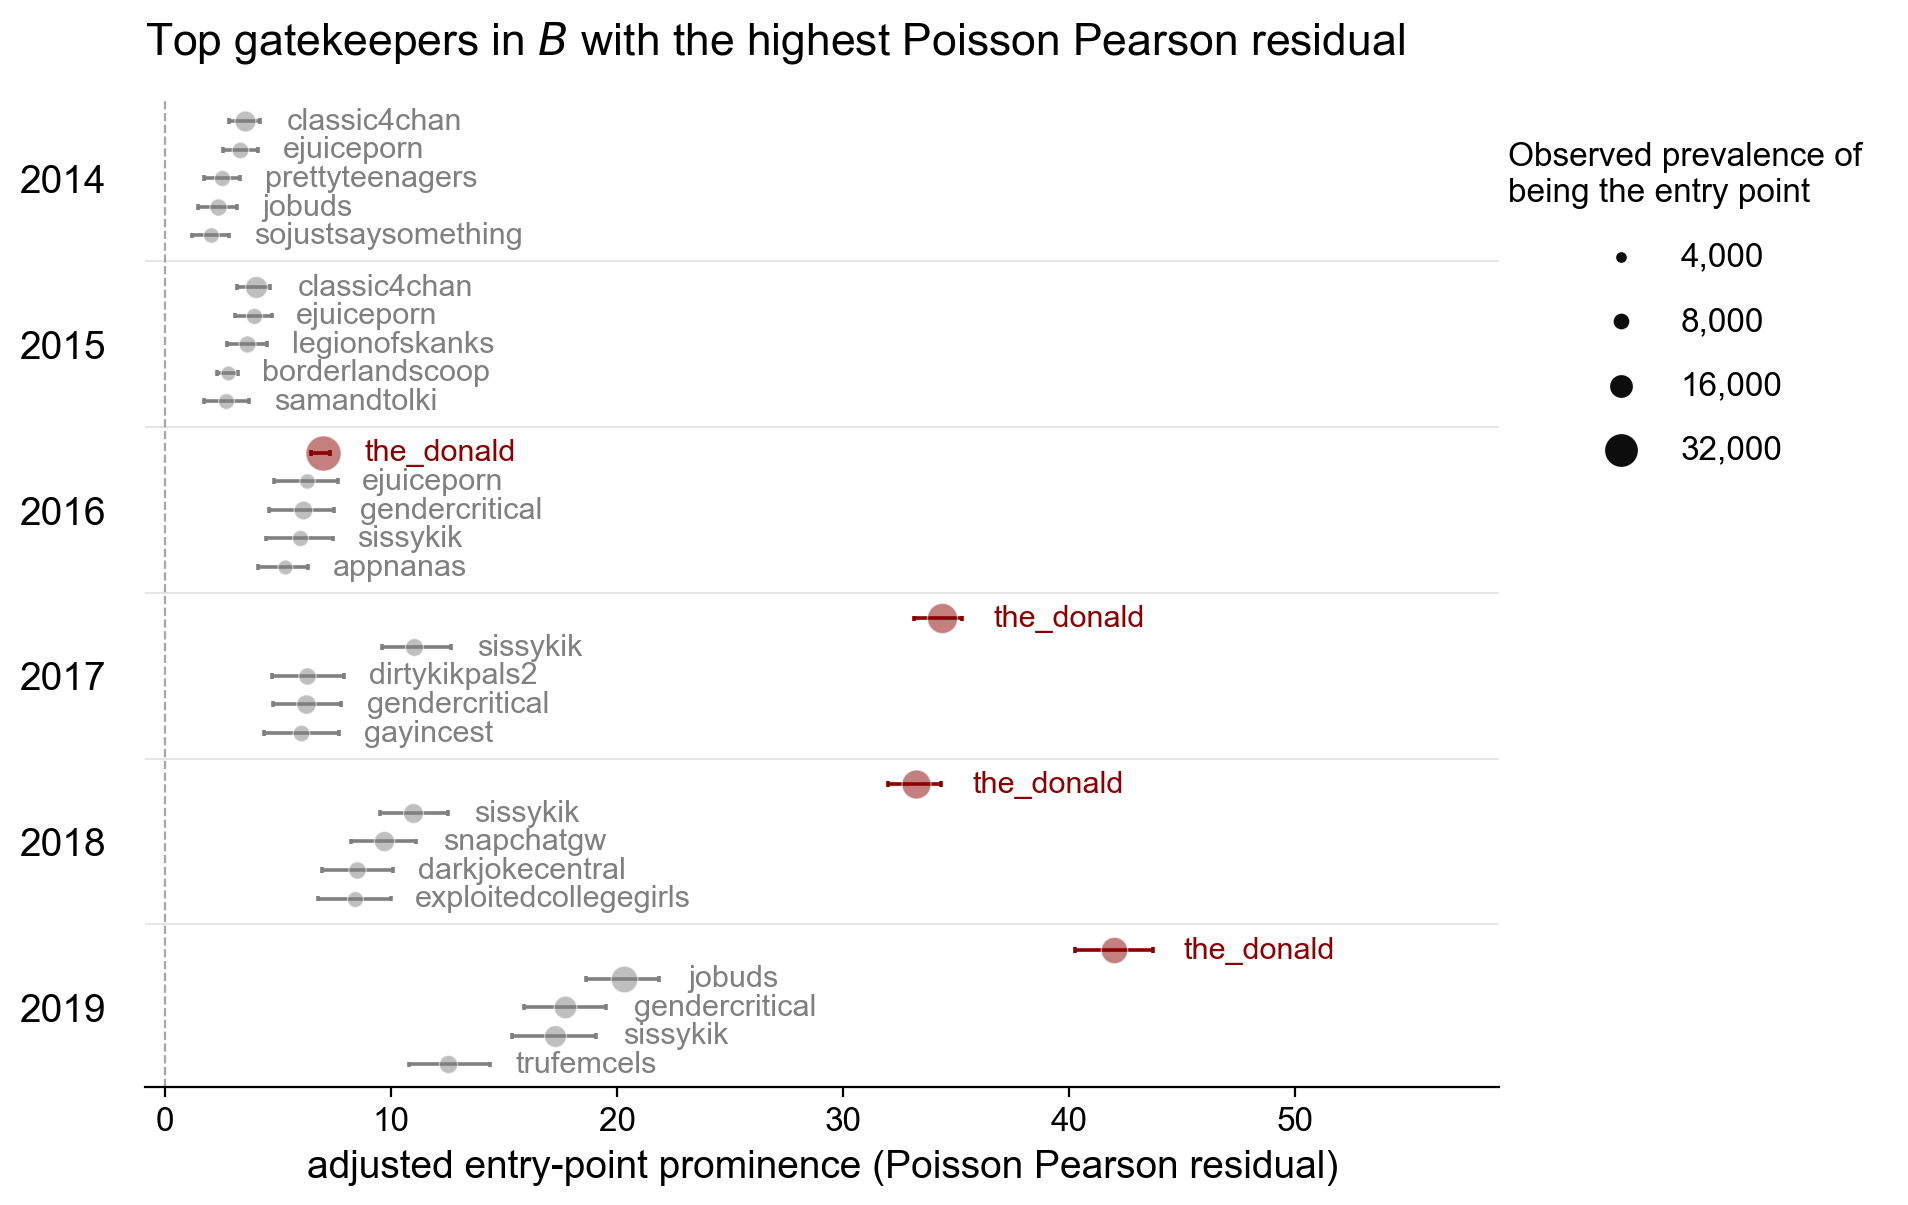

In [12]:
fig, ax = plt.subplots(figsize=(10,6.2))

OTHER_COLOR = "grey"
FOCAL_COLOR = "darkred"
MIN_AREA = 25
MAX_AREA = 160
YEAR_GAP = 0.8

max_count = top5["count_first_entry"].max()

year_centers = []
block_boundaries = []
cursor = 0

for year in PLOT_YEARS:
    d = (
        top5.loc[top5["year"] == year]
        .sort_values(["gatekeeper_score", "subreddit"], ascending=[False, True])
        .copy()
    )

    # Each subreddit gets a separate row.
    positions = cursor + np.arange(len(d))
    year_centers.append(positions.mean())

    for y, row in zip(positions, d.itertuples()):
        color = FOCAL_COLOR if row.subreddit == focal else OTHER_COLOR
        area = MIN_AREA + (MAX_AREA - MIN_AREA) * np.sqrt(row.count_first_entry / max_count)

        # Draw CI endpoints directly, preserving asymmetric intervals.
        ax.hlines(
            y, row.score_ci_low, row.score_ci_high,
            color=color, linewidth=1.3, zorder=2,
        )
        ax.vlines(
            [row.score_ci_low, row.score_ci_high],
            y - 0.10, y + 0.10,
            color=color, linewidth=1.3, zorder=2,
        )

        ax.scatter(
            row.gatekeeper_score, y,
            s=area, color=color,
            edgecolor="white", linewidth=0.5,
            alpha=0.5, zorder=3,
        )

        label = ("the_donald" if row.subreddit == focal else f"{row.subreddit}")

        # Place text beyond both the interval and the marker.
        # Extra padding accommodates larger bubbles.
        label_anchor = max(row.score_ci_high, row.gatekeeper_score)
        padding = 6 + np.sqrt(area) / 2

        ax.annotate(
            label,
            xy=(label_anchor, y),
            xytext=(padding, 0),
            textcoords="offset points",
            ha="left", va="center",
            fontsize=11, color=color,
            # fontweight="semibold" if row.subreddit == focal else "normal",
        )

    next_cursor = positions[-1] + 1 + YEAR_GAP
    block_boundaries.append((positions[-1] + next_cursor) / 2)
    cursor = next_cursor

# Subtle separators between years.
for boundary in block_boundaries[:-1]:
    ax.axhline(
        boundary, color="0.90", linewidth=0.7, zorder=0,
    )

ax.axvline(0, color="0.65", linestyle="--", linewidth=0.8, zorder=0)
ax.set_yticks(year_centers)
ax.set_yticklabels(PLOT_YEARS, fontsize=14)
ax.tick_params(axis="y", length=0, pad=14)
ax.set_ylim(positions[-1] + 0.8, -0.8)

xmin = min(0, top5["score_ci_low"].min())
xmax = max(top5["score_ci_high"].max(), top5["gatekeeper_score"].max())
span = max(xmax - xmin, 1)
ax.set_xlim(xmin - 0.02 * span, xmax + max(12, 0.35 * span))

ax.set_xlabel("adjusted entry-point prominence (Poisson Pearson residual)", fontsize=14)
# ax.set_ylabel("year of first entry", fontsize=13)
ax.set_title(r"Top gatekeepers in $B$ with the highest Poisson Pearson residual", loc="left", fontsize=16, pad=16)
ax.spines["left"].set_visible(False)
ax.grid(False)

# Rounded reference counts, appropriate for the current data range.
legend_counts = [4_000, 8_000, 16_000, 32_000]
handles = [
    ax.scatter(
        [], [],
        s=MAX_AREA * n / max_count,
        color="black", alpha=0.95,
        edgecolor="white", linewidth=0.5,
    )
    for n in legend_counts
]

ax.legend(
    handles,
    [f"{n:,}" for n in legend_counts],
    title="Observed prevalence of\nbeing the entry point",
    loc="upper right",
    bbox_to_anchor=(1.3, 1),
    # borderaxespad=0,
    frameon=False,
    fontsize=12,
    title_fontsize=12,
    labelspacing=1,
    borderpad=0.8,
)
fig.tight_layout()
# plt.savefig("../../output/261007-output-remote/gatekeeper_top5_poisson_pearson_residual.svg", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/261007-output-remote/gatekeeper_top5_poisson_pearson_residual.pdf", dpi=300, bbox_inches="tight")

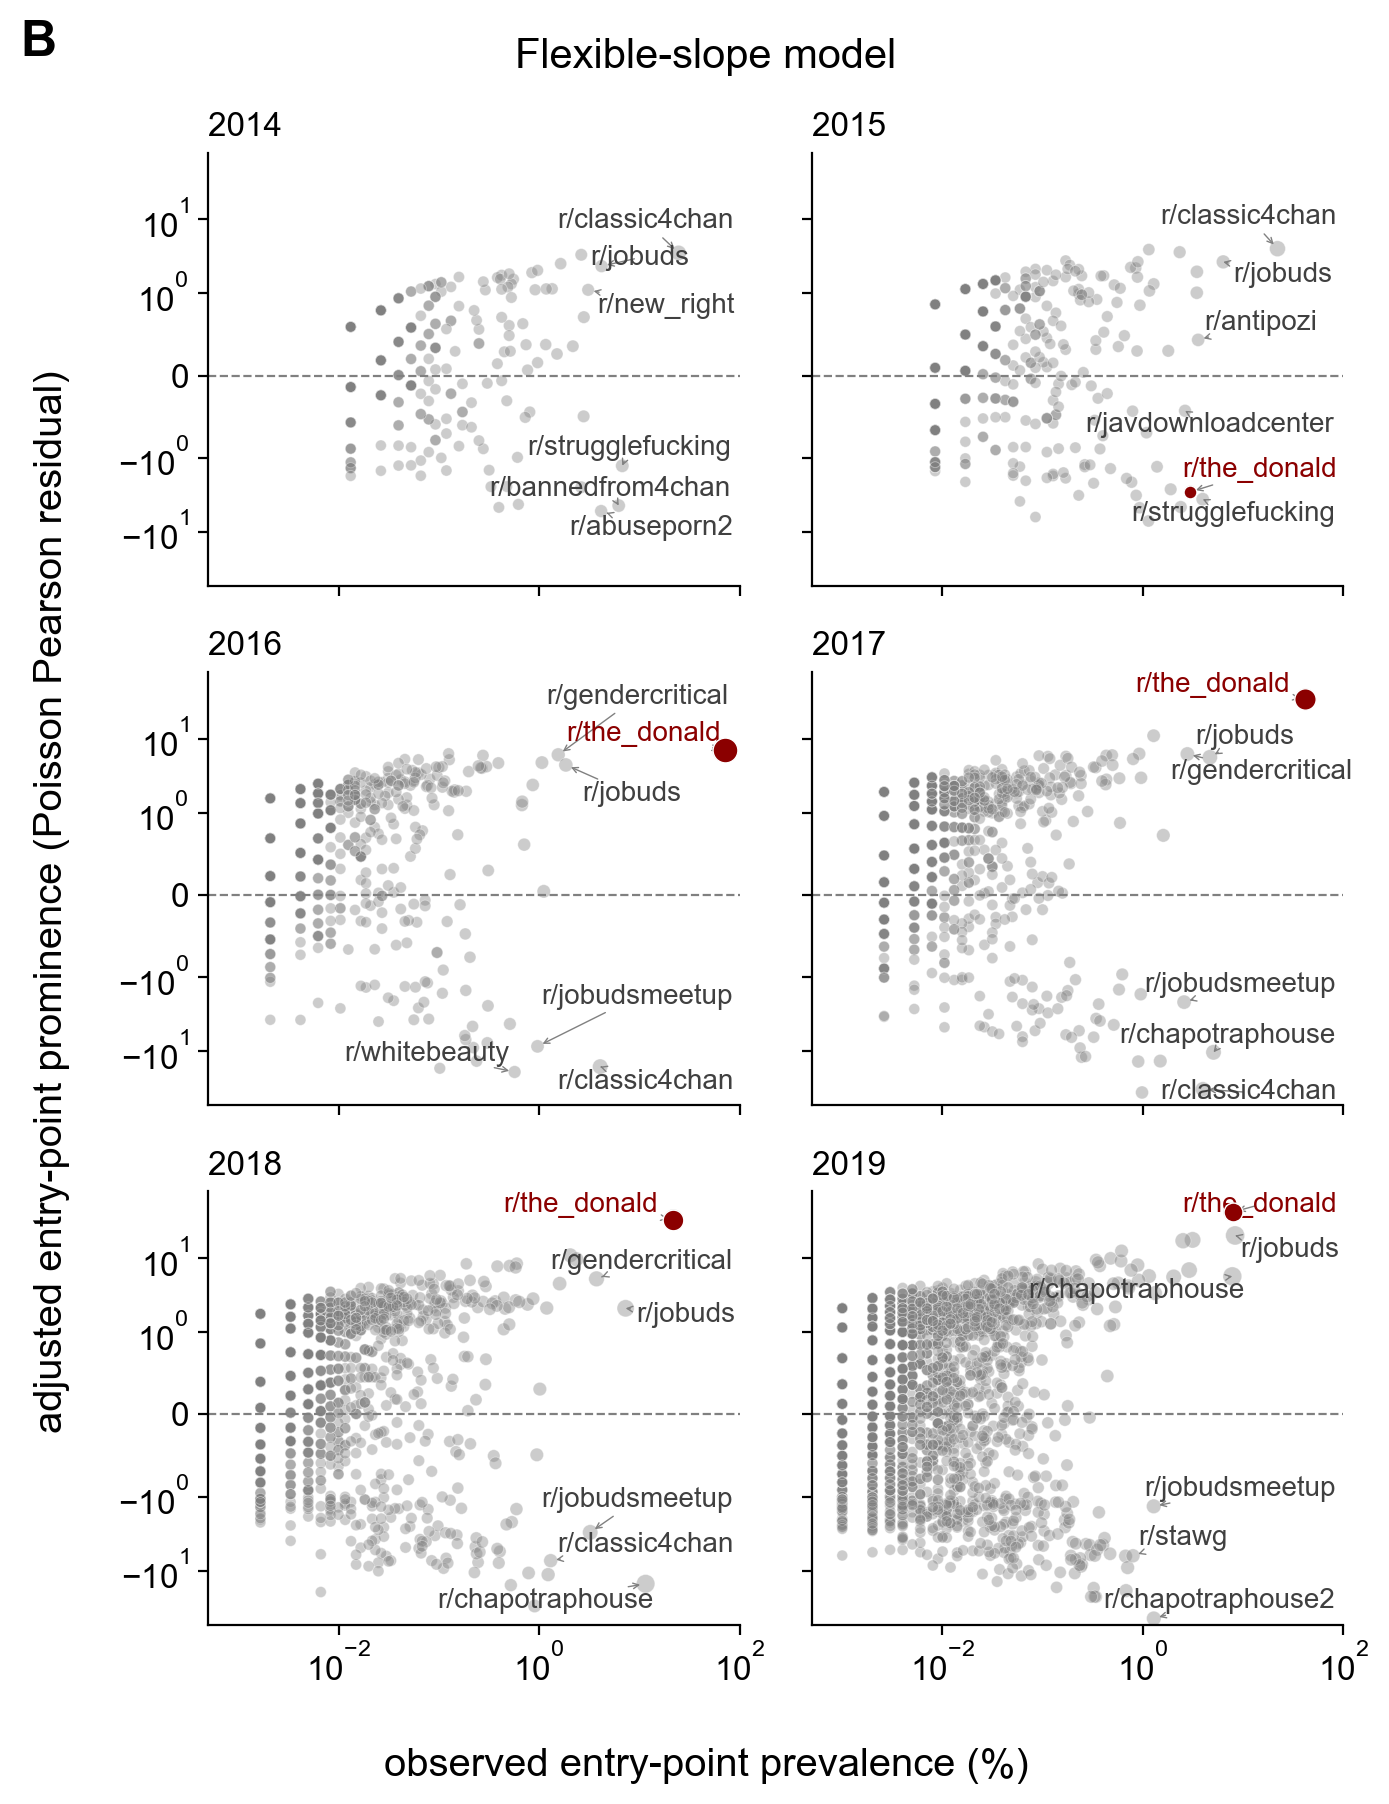

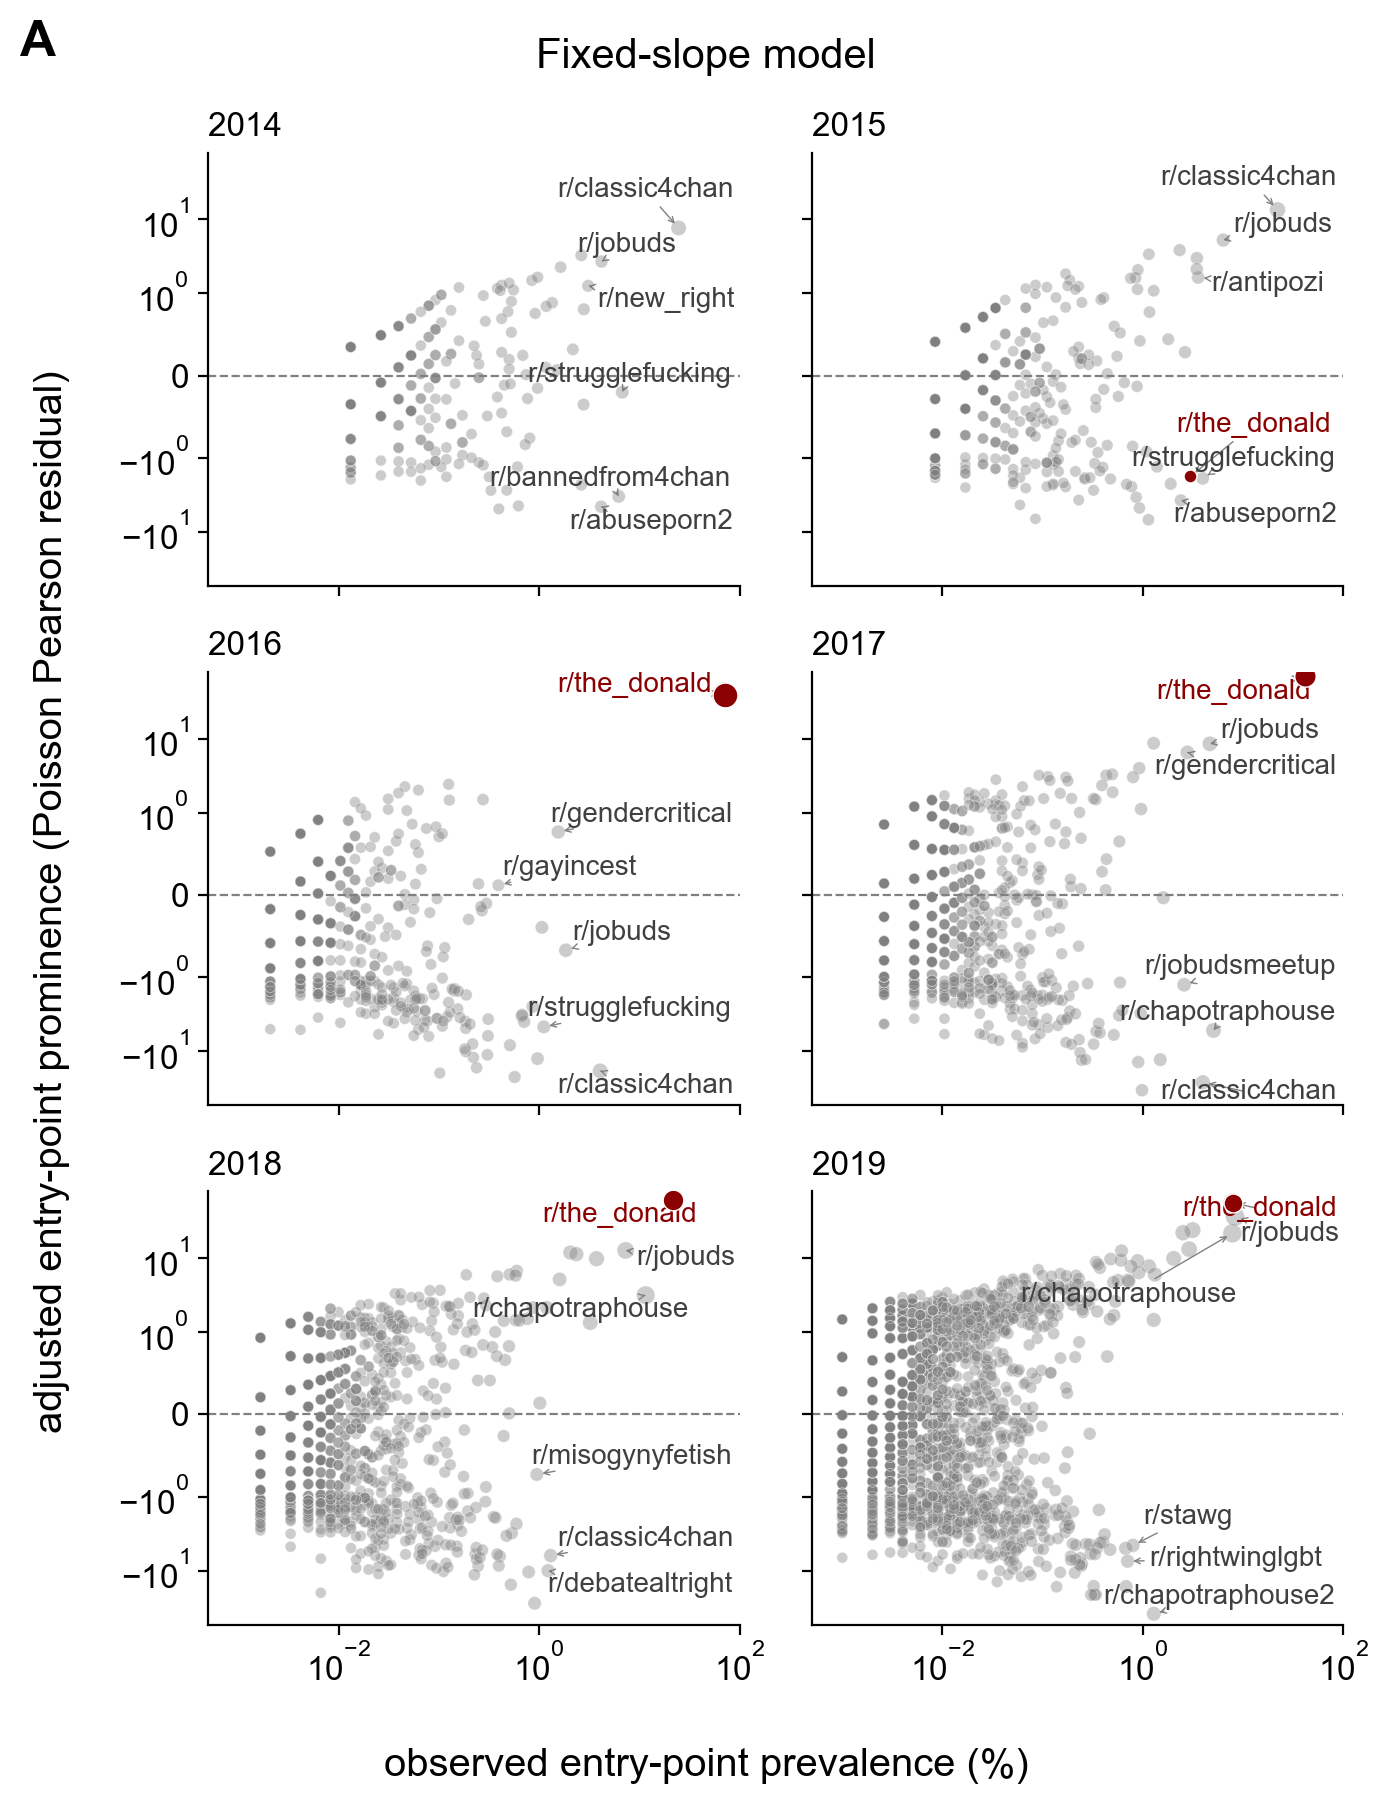

In [13]:
# for appendix, plot out entry-point prevalence vs. prominence for all subreddits, with the focal subreddit highlighted.

score_min = gatekeeper_df[["gatekeeper_score", "offset_pearson_score"]].min().min()
score_max = gatekeeper_df[["gatekeeper_score", "offset_pearson_score"]].max().max()
padding = 0.08 * (score_max - score_min)
max_count = gatekeeper_df["count_first_entry"].max()

for model, score_column in [
    ("Flexible-slope", "gatekeeper_score"),
    ("Fixed-slope", "offset_pearson_score"),
]:
    fig_compare, axes = plt.subplots(3,2, figsize=(7,9), sharex=True, sharey=True,)

    for year, ax in zip(PLOT_YEARS, axes.flat):
        d = gatekeeper_df.loc[
            (gatekeeper_df["year"] == year) & 
            (gatekeeper_df["prevalence_pct"] > 0)
        ]
        ax.scatter(
            d["prevalence_pct"], d[score_column],
            s=15 + 65 * np.sqrt(d["count_first_entry"] / max_count),
            color="grey", alpha=0.4, edgecolors="white", linewidths=0.3,
        )

        focal_d = d.loc[d["subreddit"] == focal]
        ax.scatter(
            focal_d["prevalence_pct"], focal_d[score_column],
            s=15 + 65 * np.sqrt(focal_d["count_first_entry"] / max_count),
            color="darkred", edgecolors="white", linewidths=0.5, zorder=4,
        )
        ax.axhline(0, color="0.5", ls="--", lw=0.8)
        ax.set_xscale("log")
        ax.set_yscale("symlog", linthresh=1)
        ax.set_ylim(score_min - padding, score_max + padding)
        ax.set_xlim(gatekeeper_df.loc[gatekeeper_df["prevalence_pct"] > 0, "prevalence_pct"].min() / 2, 100)
        ax.set_title(str(year), loc="left", fontsize=12)
        ax.grid(False)

        # Label the three most frequent entry points on each side of zero,
        # requiring at least 20 entry-point users. Always include the focal subreddit.
        label_pool = d.loc[d["count_first_entry"] >= 20]
        label_rows = pd.concat([
            label_pool.loc[label_pool[score_column] > 0].nlargest(3, "count_first_entry"),
            label_pool.loc[label_pool[score_column] < 0].nlargest(3, "count_first_entry"),
            focal_d,
        ]).drop_duplicates("subreddit")

        texts = [
            ax.text(
                row.prevalence_pct, getattr(row, score_column),
                "r/" + row.subreddit, fontsize=10,
                color="darkred" if row.subreddit == focal else "0.25",
            )
            for row in label_rows.itertuples()
        ]
        adjust_text(
            texts, ax=ax, expand=(1.1, 1.2), force_text=(0.4, 0.6), iter_lim=150, min_arrow_len=0,
            arrowprops=dict(arrowstyle="->", color="0.5", lw=0.5, mutation_scale=5,),
        )
    fig_compare.text(
        0.01, 0.99, "A" if model == "Fixed-slope" else "B", 
        ha="left", va="top", fontsize=18, fontweight="bold",
    )
    fig_compare.suptitle(model + " model", fontsize=15)
    fig_compare.supxlabel("observed entry-point prevalence (%)")
    fig_compare.supylabel("adjusted entry-point prominence (Poisson Pearson residual)")
    fig_compare.tight_layout(rect=(0.025, 0.02, 1, 0.95))
    plt.tight_layout()
    # plt.show()
    # fig_compare.savefig(f"gatekeeper_prevalence_{model}.pdf", bbox_inches="tight")
    # plt.savefig(f"../../output/261012-output-remote/entry_point_prevalance_prominence_2014_2019_{model}.png", dpi=300, bbox_inches="tight")
    # plt.savefig(f"../../output/261012-output-remote/entry_point_prevalance_prominence_2014_2019_{model}.pdf", dpi=300, bbox_inches="tight")

